In [ ]:
import pandas as pd
import numpy as np
import pennylane as qml
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_curve, auc
from sklearn.utils.class_weight import compute_class_weight
from imblearn.over_sampling import SMOTE
from scipy.stats import mode
import time
import os
from joblib import dump, load
import os
from scipy.stats import mode
from tqdm import tqdm



# Parameters
BATCH_SIZE = 300
NUM_BATCHES = 10
NUM_FEATURES = 4
SEED = 42
USE_QSIM = True
SAVE_RESULTS = True
MODEL_DIR = "saved_models"
KERNEL_DIR = "saved_kernels"
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(KERNEL_DIR, exist_ok=True)

In [2]:
print("Loading dataset...")
df = pd.read_csv('IoT_Network_Intrusion_Dataset.csv', delimiter=',', encoding='utf-8')

Loading dataset...


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 625783 entries, 0 to 625782
Data columns (total 86 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Flow_ID            625783 non-null  object 
 1   Src_IP             625783 non-null  object 
 2   Src_Port           625783 non-null  int64  
 3   Dst_IP             625783 non-null  object 
 4   Dst_Port           625783 non-null  int64  
 5   Protocol           625783 non-null  int64  
 6   Timestamp          625783 non-null  object 
 7   Flow_Duration      625783 non-null  int64  
 8   Tot_Fwd_Pkts       625783 non-null  int64  
 9   Tot_Bwd_Pkts       625783 non-null  int64  
 10  TotLen_Fwd_Pkts    625783 non-null  float64
 11  TotLen_Bwd_Pkts    625783 non-null  float64
 12  Fwd_Pkt_Len_Max    625783 non-null  float64
 13  Fwd_Pkt_Len_Min    625783 non-null  float64
 14  Fwd_Pkt_Len_Mean   625783 non-null  float64
 15  Fwd_Pkt_Len_Std    625783 non-null  float64
 16  Bw

In [3]:
columns_to_drop = ['Flow_ID', 'Src_IP', 'Dst_IP', 'Timestamp', 'Cat', 'Sub_Cat']
df.drop(columns=columns_to_drop, inplace=True, errors='ignore')

df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.fillna(df.mean(numeric_only=True), inplace=True)

le = LabelEncoder()
df['Label'] = le.fit_transform(df['Label'])

print(f"Classes: {le.classes_}")
feature_names = df.columns

X = df.drop('Label', axis=1)
y = df['Label']

X_train_full, X_test, y_train_full, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print(f"Original class distribution: {np.bincount(y_train_full)}")

scaler = StandardScaler()
X_train_full = scaler.fit_transform(X_train_full)
# X_test = scaler.transform(X_test)
X_test_scaled = scaler.transform(X_test)


from sklearn.decomposition import PCA

pca = PCA(n_components=NUM_FEATURES, random_state=42)
X_train_pca = pca.fit_transform(X_train_full)
X_test_pca = pca.transform(X_test_scaled)

print("Features Selected: ")
for i, component in enumerate(pca.components_):
    # Get the index of the feature with the largest absolute value in this component
    important_idx = np.argmax(np.abs(component))
    print(f"Principal Component {i+1}: most important feature is '{feature_names[important_idx]}'")

X_train_full = X_train_pca
X_test_q = X_test_pca[:100]

# X_train_full = X_train_full[:, :NUM_FEATURES]
# # X_test = X_test[:, :NUM_FEATURES]
# X_test_q = X_test_scaled[:100, :NUM_FEATURES]   # apply SMOTE


Classes: ['Anomaly' 'Normal']
Original class distribution: [468566  32060]
Features Selected: 
Principal Component 1: most important feature is 'Pkt_Len_Mean'
Principal Component 2: most important feature is 'Flow_Duration'
Principal Component 3: most important feature is 'Bwd_Header_Len'
Principal Component 4: most important feature is 'Flow_IAT_Min'


In [4]:
X_train_full.shape
X_train_full[:5]


array([[-2.04434919, -2.78201418, -0.99654488, -0.26956809],
       [ 2.84610968,  1.27938091, -1.29352092, -0.43612075],
       [ 2.37020812,  1.40625121,  2.69031424, -1.06783929],
       [-2.0594    , -2.59172315, -0.80700663, -0.13049992],
       [ 4.04515598,  2.05228471, -2.61500574,  0.85751598]])

In [5]:
if USE_QSIM:
    # dev = qml.device("cirq.qsim", wires=NUM_FEATURES)
    dev = qml.device("default.qubit", wires=NUM_FEATURES)
    # dev = qml.device("lightning.gpu", wires=NUM_FEATURES)
    # dev = qml.device("cirq.qsim", wires=NUM_FEATURES, backend="qsim_gpu")
    # device default qubit
    print("Using QSim Simulator backend.")
else:
    dev = qml.device("lightning.qubit", wires=NUM_FEATURES)
    print("Using Lightning.qubit backend.")

@qml.qnode(dev)
def kernel_circuit(x1, x2):
    qml.AngleEmbedding(x1, wires=range(NUM_FEATURES))
    for wire in range(NUM_FEATURES):
        qml.Hadamard(wires=wire)
    qml.AngleEmbedding(x2, wires=range(NUM_FEATURES))
    return qml.probs(wires=range(NUM_FEATURES))

def compute_kernel_matrix(X1, X2):
    n_samples_1, n_samples_2 = len(X1), len(X2)
    kernel_matrix = np.zeros((n_samples_1, n_samples_2))
    for i in range(n_samples_1):
        if i % 10 == 0:
            print(f"Computing row {i+1}/{n_samples_1}...")
        for j in range(n_samples_2):
            kernel_matrix[i, j] = kernel_circuit(X1[i], X2[j])[0]
    return kernel_matrix

Using QSim Simulator backend.


In [20]:
total_samples = BATCH_SIZE * NUM_BATCHES
X_train_full = X_train_full[:total_samples]
y_train_full = y_train_full[:total_samples]

for batch_idx in range(NUM_BATCHES):
    start = batch_idx * BATCH_SIZE
    end = start + BATCH_SIZE
    print(f"\nBatch {batch_idx+1}/{NUM_BATCHES} — samples {start}:{end}")

    X_batch = X_train_full[start:end]
    y_batch = y_train_full[start:end]

    # SMOTE balancing
    smote = SMOTE(random_state=42)
    X_bal, y_bal = smote.fit_resample(X_batch, y_batch)
    print(X_bal.shape)
    print(y_bal.shape)
    # X_bal = X_bal[:300]

    # Shuffle to mix classes
    from sklearn.utils import shuffle
    X_bal, y_bal = shuffle(X_bal, y_bal, random_state=SEED)

    # Find indices for each class
    class0_idx = np.where(y_bal == 0)[0]
    class1_idx = np.where(y_bal == 1)[0]

    n_per_class = 150  # For 300 samples total
    # If not enough samples in a class, take as many as possible
    n0 = min(n_per_class, len(class0_idx))
    n1 = min(n_per_class, len(class1_idx))

    selected_idx = np.concatenate([class0_idx[:n0], class1_idx[:n1]])
    X_bal = X_bal[selected_idx]
    y_bal = y_bal[selected_idx]

    print("Final class balance:", np.bincount(y_bal))
    np.save(f"{KERNEL_DIR}/X_balanced_{batch_idx}.npy", X_bal)


    # Computing kernel matrix
    training_kernel = compute_kernel_matrix(X_bal, X_bal)
    # test_kernel = compute_kernel_matrix(X_test_scaled[:, :4], X_bal)
    smote2 = SMOTE(random_state=42, k_neighbors=2)
    X_test_q_bal, y_test_bal = smote2.fit_resample(X_test_q, y_test[:len(X_test_q)])

    # class0_idx = np.where(y_test == 0)[0]
    # class1_idx = np.where(y_test == 1)[0]
    # n_per_class = 50
    # n0 = min(n_per_class, len(class0_idx))
    # n1 = min(n_per_class, len(class1_idx))
    # selected_idx = np.concatenate([class0_idx[:n0], class1_idx[:n1]])
    # X_test_q_bal = X_test_q_bal[selected_idx]
    # y_test_bal = y_test_bal[selected_idx]
    
    test_kernel = compute_kernel_matrix(X_test_q_bal, X_bal)

    # Training SVM
    # class_weights = compute_class_weight('balanced', classes=np.unique(y_batch), y=y_batch)
    # class_weights_dict = {i: w for i, w in enumerate(class_weights)}
    # model = SVC(kernel="precomputed", class_weight=class_weights_dict, C=1)
    model = SVC(kernel="precomputed", C=1)
    model.fit(training_kernel, y_bal)

    # Saving model & balanced X for prediction
    dump(model, f"{MODEL_DIR}/model_batch_{batch_idx}.joblib")

    del model
    del X_bal
    del training_kernel
    del test_kernel



Batch 1/10 — samples 0:300
(564, 4)
(564,)
Final class balance: [279  21]
Computing row 1/300...
Computing row 11/300...
Computing row 21/300...
Computing row 31/300...
Computing row 41/300...
Computing row 51/300...
Computing row 61/300...
Computing row 71/300...
Computing row 81/300...
Computing row 91/300...
Computing row 101/300...
Computing row 111/300...
Computing row 121/300...
Computing row 131/300...
Computing row 141/300...
Computing row 151/300...
Computing row 161/300...
Computing row 171/300...
Computing row 181/300...
Computing row 191/300...
Computing row 201/300...
Computing row 211/300...
Computing row 221/300...
Computing row 231/300...
Computing row 241/300...
Computing row 251/300...
Computing row 261/300...
Computing row 271/300...
Computing row 281/300...
Computing row 291/300...
Computing row 1/190...
Computing row 11/190...
Computing row 21/190...
Computing row 31/190...
Computing row 41/190...
Computing row 51/190...
Computing row 61/190...
Computing row 71/19


Starting ensemble prediction via majority voting...


Ensemble Voting:   0%|          | 0/10 [00:00<?, ?it/s]

Computing row 1/190...
Computing row 11/190...
Computing row 21/190...
Computing row 31/190...
Computing row 41/190...
Computing row 51/190...
Computing row 61/190...
Computing row 71/190...
Computing row 81/190...
Computing row 91/190...
Computing row 101/190...
Computing row 111/190...
Computing row 121/190...
Computing row 131/190...
Computing row 141/190...
Computing row 151/190...
Computing row 161/190...
Computing row 171/190...
Computing row 181/190...


Ensemble Voting:  10%|█         | 1/10 [01:23<12:31, 83.53s/it]

Computing row 1/190...
Computing row 11/190...
Computing row 21/190...
Computing row 31/190...
Computing row 41/190...
Computing row 51/190...
Computing row 61/190...
Computing row 71/190...
Computing row 81/190...
Computing row 91/190...
Computing row 101/190...
Computing row 111/190...
Computing row 121/190...
Computing row 131/190...
Computing row 141/190...
Computing row 151/190...
Computing row 161/190...
Computing row 171/190...
Computing row 181/190...


...

Computing row 1/190...
Computing row 11/190...
Computing row 21/190...
Computing row 31/190...
Computing row 41/190...
Computing row 51/190...
Computing row 61/190...
Computing row 71/190...
Computing row 81/190...
Computing row 91/190...
Computing row 101/190...
Computing row 111/190...
Computing row 121/190...
Computing row 131/190...
Computing row 141/190...
Computing row 151/190...
Computing row 161/190...
Computing row 171/190...
Computing row 181/190...


Ensemble Voting:  90%|█████████ | 9/10 [12:27<01:22, 82.71s/it]

Computing row 1/190...
Computing row 11/190...
Computing row 21/190...
Computing row 31/190...
Computing row 41/190...
Computing row 51/190...
Computing row 61/190...
Computing row 71/190...
Computing row 81/190...
Computing row 91/190...
Computing row 101/190...
Computing row 111/190...
Computing row 121/190...
Computing row 131/190...
Computing row 141/190...
Computing row 151/190...
Computing row 161/190...
Computing row 171/190...
Computing row 181/190...


Ensemble Voting: 100%|██████████| 10/10 [13:49<00:00, 82.92s/it]
/home/ritvik/Code/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/ritvik/Code/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/ritvik/Code/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{me


✅ Ensemble Accuracy: 0.9421
Classification Report:
               precision    recall  f1-score   support

           0       0.94      1.00      0.97       179
           1       0.00      0.00      0.00        11

    accuracy                           0.94       190
   macro avg       0.47      0.50      0.49       190
weighted avg       0.89      0.94      0.91       190



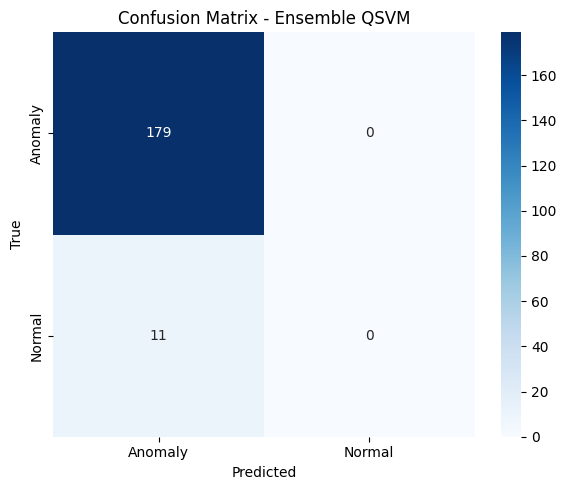

In [21]:
print("\nStarting ensemble prediction via majority voting...")
all_preds = []

for batch_idx in tqdm(range(NUM_BATCHES), desc="Ensemble Voting"):
    model_path = os.path.join(MODEL_DIR, f"model_batch_{batch_idx}.joblib")
    X_path = os.path.join(KERNEL_DIR, f"X_balanced_{batch_idx}.npy")

    if os.path.exists(model_path) and os.path.exists(X_path):
        model = load(model_path)
        X_batch = np.load(X_path)
        test_kernel = compute_kernel_matrix(X_test_q_bal, X_batch)
        pred = model.predict(test_kernel)
        all_preds.append(pred)

# Majority voting
all_preds = np.array(all_preds)
final_preds, _ = mode(all_preds, axis=0)

# Evaluatation
y_test_small = y_test[:190]
acc = accuracy_score(y_test_small, final_preds)
print(f"\n✅ Ensemble Accuracy: {acc:.4f}")
print("Classification Report:\n", classification_report(y_test_small, final_preds))

cm = confusion_matrix(y_test_small, final_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap="Blues", xticklabels=le.classes_, yticklabels=le.classes_)
plt.title("Confusion Matrix - Ensemble QSVM")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.show()


---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [ ]:
total_samples = X_train_full.shape[0]
num_batches = (total_samples + BATCH_SIZE - 1) // BATCH_SIZE

batch_models = []
batch_results = []

# Precompute fixed testing kernel later
X_test_global = X_test  # save now for later

print("\n🚀 Starting Batch Training...")

for batch_idx in range(num_batches):
    start_idx = batch_idx * BATCH_SIZE
    end_idx = min(start_idx + BATCH_SIZE, total_samples)

    print(f"\n🚀 Processing batch {batch_idx+1}/{num_batches} (samples {start_idx} to {end_idx})...")
    
    X_batch = X_train_full[start_idx:end_idx]
    y_batch = y_train_full[start_idx:end_idx]

    smote_tomek = SMOTETomek(random_state=SEED)
    X_batch_balanced, y_batch_balanced = smote_tomek.fit_resample(X_batch, y_batch)

    print(f"Balanced batch shape: {X_batch_balanced.shape}")

    # Compute training kernel
    start_time = time.time()
    training_kernel = compute_kernel_matrix(X_batch_balanced, X_batch_balanced)
    # Compute testing kernel (X_test vs batch)
    testing_kernel = compute_kernel_matrix(X_test_global, X_batch_balanced)
    kernel_time = time.time() - start_time
    print(f"Kernel computation time: {kernel_time:.2f} seconds.")

    # Train SVM
    class_weights = compute_class_weight('balanced', classes=np.unique(y_batch_balanced), y=y_batch_balanced)
    class_weights_dict = {i: weight for i, weight in enumerate(class_weights)}
    
    svm = SVC(kernel='precomputed', class_weight=class_weights_dict, C=1)
    svm.fit(training_kernel, y_batch_balanced)

    # Save model
    batch_models.append((svm, X_batch_balanced.copy()))

    # Evaluate immediately (optional)
    y_pred = svm.predict(testing_kernel)
    acc = accuracy_score(y_test, y_pred)
    print(f"🎯 Batch {batch_idx+1} Accuracy: {acc:.4f}")

    batch_results.append({
        'batch': batch_idx+1,
        'start_sample': start_idx,
        'end_sample': end_idx,
        'batch_size': X_batch_balanced.shape[0],
        'accuracy': acc,
        'kernel_time_sec': kernel_time,
    })

In [ ]:
print("\n🧠 Starting Majority Voting Ensembling...")

all_batch_predictions = []

for model_idx, (svm_model, X_batch_balanced) in enumerate(batch_models):
    print(f"Predicting using batch model {model_idx+1}...")
    testing_kernel = compute_kernel_matrix(X_test_global, X_batch_balanced)
    y_pred = svm_model.predict(testing_kernel)
    all_batch_predictions.append(y_pred)

# Stack all predictions: shape (num_batches, num_samples)
all_batch_predictions = np.array(all_batch_predictions)

# Majority vote across batches
final_predictions, _ = mode(all_batch_predictions, axis=0)
final_predictions = final_predictions.ravel()

# Evaluate final ensemble
ensemble_accuracy = accuracy_score(y_test, final_predictions)
ensemble_report = classification_report(y_test, final_predictions)
ensemble_cm = confusion_matrix(y_test, final_predictions)

print(f"\n✅ Ensemble Accuracy on Test Set: {ensemble_accuracy:.4f}")
print("\nClassification Report (Ensemble):\n")
print(ensemble_report)

# Plot confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(ensemble_cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Anomaly", "Normal"], yticklabels=["Anomaly", "Normal"])
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - Ensemble QSVM")
plt.show()


In [ ]:
if SAVE_RESULTS:
    result_df = pd.DataFrame(batch_results)
    result_df.to_csv('qsvm_batch_results.csv', index=False)
    print("\n✅ Batch results saved to qsvm_batch_results.csv")